# A tour of ggtext

**ggtext** adds rich text (Markdown, HTML and CSS) to matplotlib and plotnine plots: bold and italic words, colors, sizes, sub- and superscripts, images, word-wrapped text boxes, and more.

This notebook walks through the main features. Run it top to bottom.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from plotnine import (
    aes,
    expand_limits,
    geom_col,
    geom_point,
    ggplot,
    labs,
    scale_color_manual,
    scale_x_discrete,
    theme,
    theme_minimal,
)
from plotnine.data import penguins

import ggtext
from ggtext import element_markdown, element_textbox_simple, geom_richtext, geom_textbox

%matplotlib inline

## 1. Markdown in a plotnine title

Swap `element_text()` for `element_markdown()` in `theme()`, then write Markdown or HTML in your labels. Coloring words in the title can replace the legend entirely.

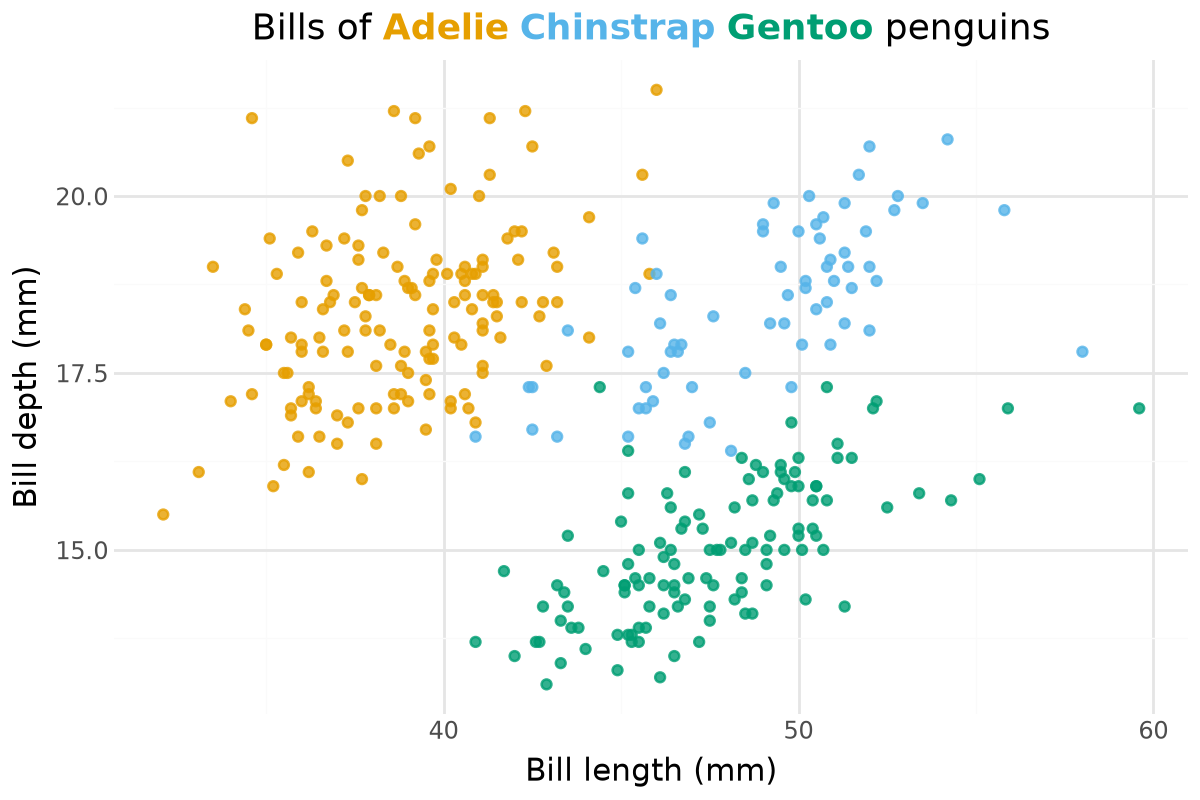

In [2]:
colors = {"Adelie": "#E69F00", "Chinstrap": "#56B4E9", "Gentoo": "#009E73"}
title = " ".join(f"<span style='color:{c}'>**{s}**</span>" for s, c in colors.items())

(
    ggplot(penguins.dropna(), aes("bill_length_mm", "bill_depth_mm", color="species"))
    + geom_point(alpha=0.8)
    + scale_color_manual(values=colors, guide=None)
    + labs(
        title=f"Bills of {title} penguins", x="Bill length (mm)", y="Bill depth (mm)"
    )
    + theme_minimal()
    + theme(plot_title=element_markdown(size=13), figure_size=(6, 4))
)

## 2. A long subtitle that wraps

`element_textbox_simple()` word-wraps text to the width of the panel area. Pass `fill`, `padding` and `r` to draw a box.

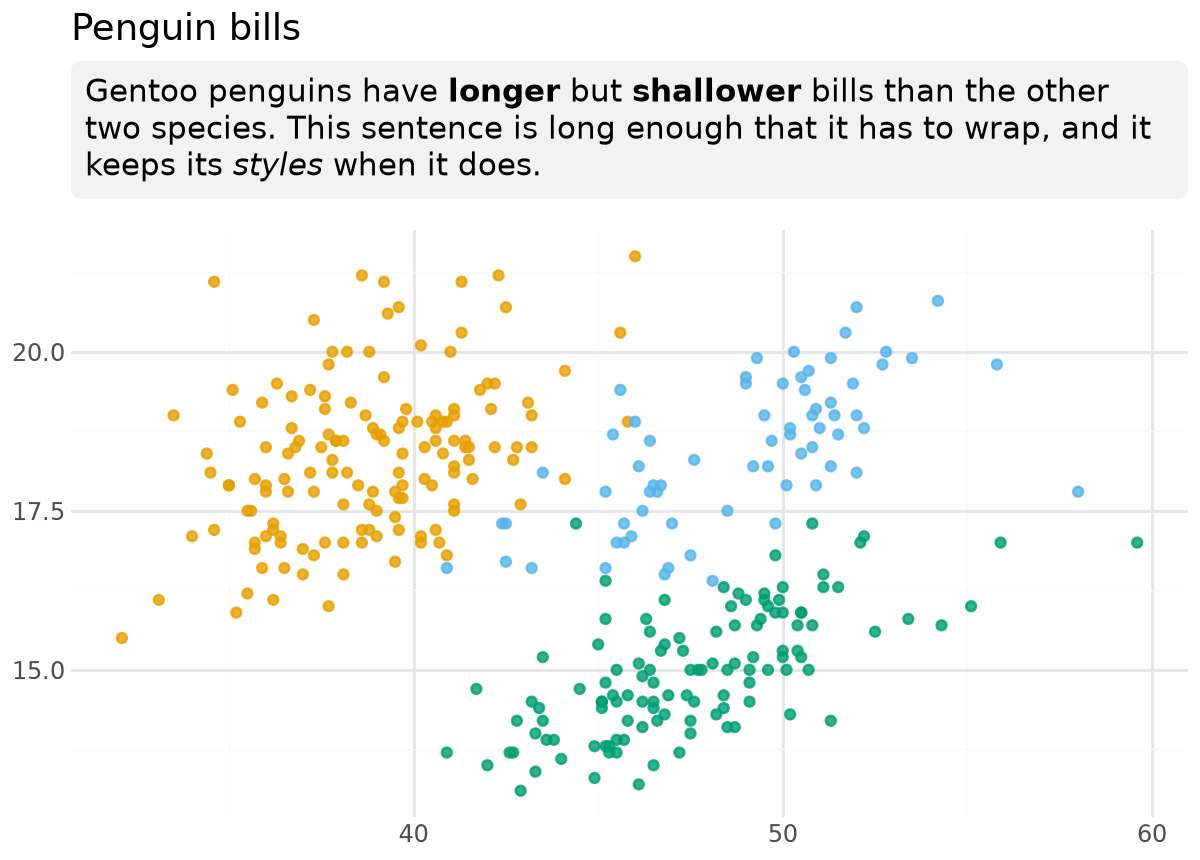

In [3]:
subtitle = (
    "Gentoo penguins have **longer** but **shallower** bills than the other two species. "
    "This sentence is long enough that it has to wrap, and it keeps its *styles* when it does."
)
(
    ggplot(penguins.dropna(), aes("bill_length_mm", "bill_depth_mm", color="species"))
    + geom_point(alpha=0.8)
    + scale_color_manual(values=colors, guide=None)
    + labs(title="Penguin bills", subtitle=subtitle, x="", y="")
    + theme_minimal()
    + theme(
        plot_subtitle=element_textbox_simple(
            fill="#F2F2F2", padding=5, r=4, margin={"b": 8}
        ),
        figure_size=(6, 4.3),
    )
)

## 3. Axis titles and tick labels

Tick labels work too, at any rotation. Use `<sub>` and `<sup>` for units.

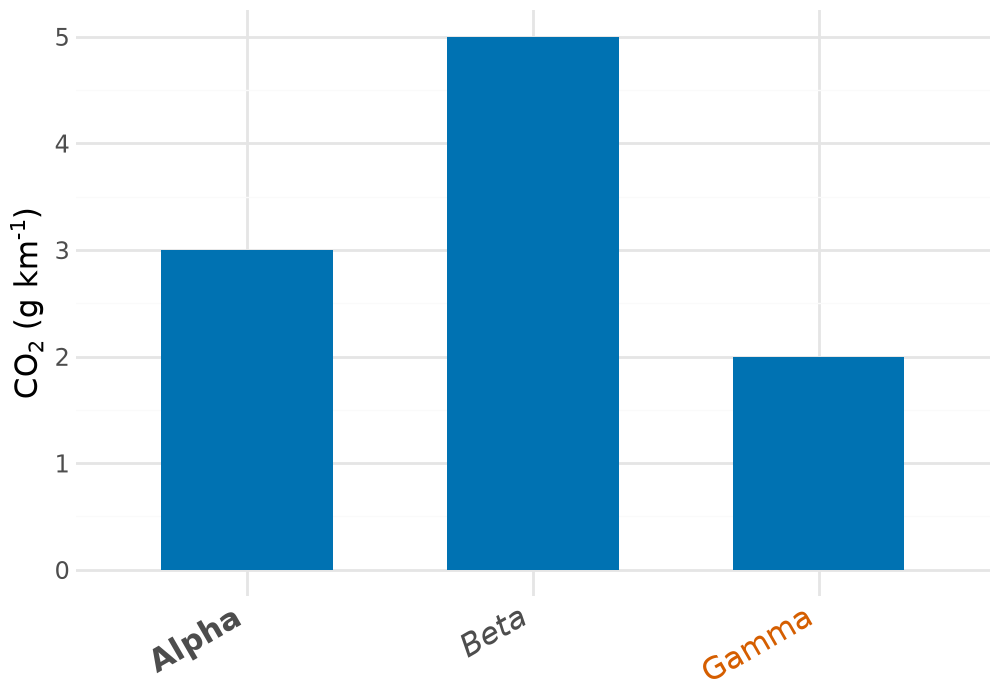

In [4]:
df = pd.DataFrame({"g": ["a", "b", "c"], "v": [3, 5, 2]})
(
    ggplot(df, aes("g", "v"))
    + geom_col(fill="#0072B2", width=0.6)
    + scale_x_discrete(
        labels=["**Alpha**", "*Beta*", "<span style='color:#D55E00'>Gamma</span>"]
    )
    + labs(x="", y="CO<sub>2</sub> (g km<sup>-1</sup>)")
    + theme_minimal()
    + theme(
        axis_text_x=element_markdown(rotation=30, ha="right", size=11),
        axis_title_y=element_markdown(),
        figure_size=(5, 3.5),
    )
)

## 4. Rich text labels in the data: `geom_richtext()` and `geom_textbox()`

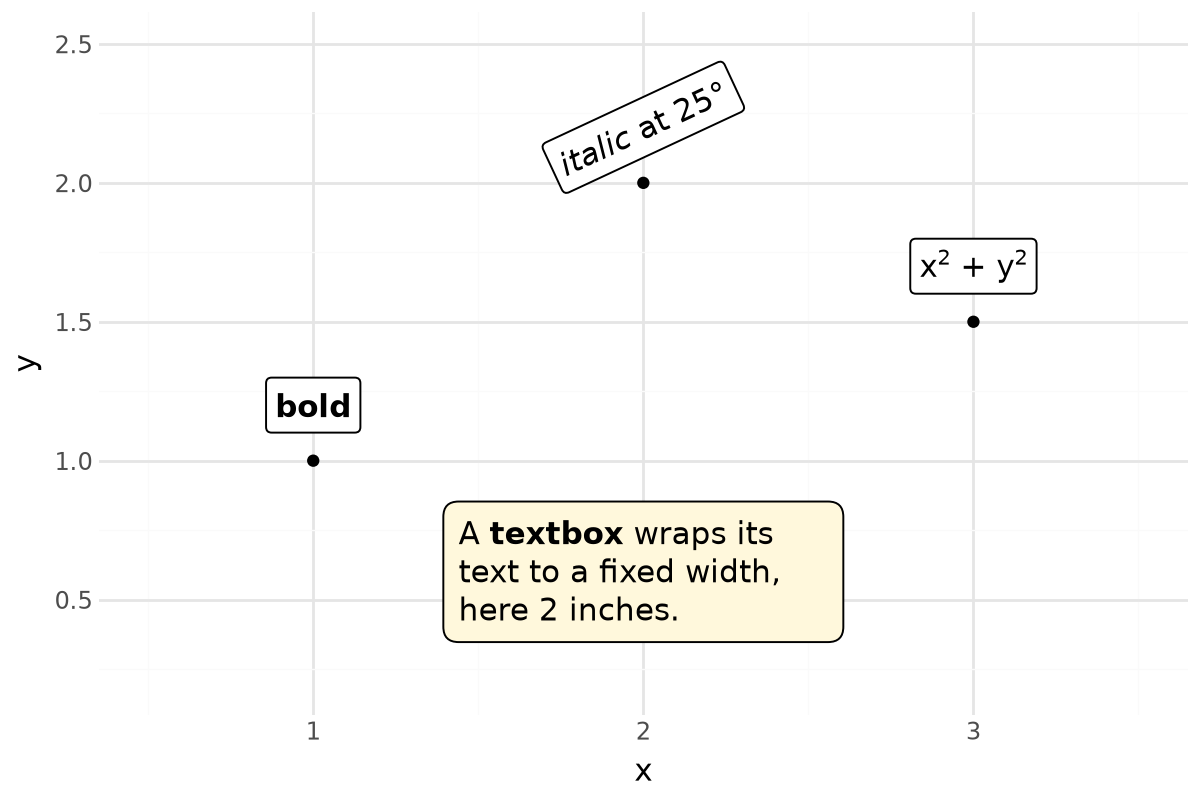

In [5]:
pts = pd.DataFrame(
    {
        "x": [1, 2, 3],
        "y": [1, 2, 1.5],
        "label": ["**bold**", "*italic* at 25°", "x<sup>2</sup> + y<sup>2</sup>"],
        "angle": [0, 25, 0],
    }
)
box = pd.DataFrame(
    {
        "x": [2],
        "y": [0.6],
        "label": ["A **textbox** wraps its text to a fixed width, here 2 inches."],
    }
)
(
    ggplot(pts, aes("x", "y"))
    + geom_point()
    + geom_richtext(aes(label="label", angle="angle"), nudge_y=0.2)
    + geom_textbox(aes(label="label"), data=box, width="2in", fill="#FFF8DC")
    + expand_limits(y=[0.2, 2.5], x=[0.5, 3.5])
    + theme_minimal()
    + theme(figure_size=(6, 4))
)

## 5. Plain matplotlib

Everything works without plotnine as well. The helpers mirror matplotlib's own functions.

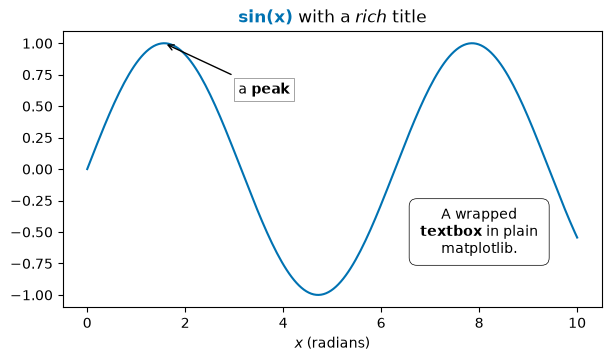

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
x = np.linspace(0, 10, 200)
ax.plot(x, np.sin(x), color="#0072B2")
ggtext.set_title(
    ax, "<span style='color:#0072B2'>**sin(x)**</span> with a *rich* title"
)
ggtext.set_xlabel(ax, "*x* (radians)")
ggtext.annotate(
    ax,
    "a **peak**",
    xy=(np.pi / 2, 1),
    xytext=(3, 0.6),
    arrowprops=dict(arrowstyle="->"),
    fill="white",
    box_color="gray",
    padding=3,
)
ggtext.textbox(ax, 8, -0.5, "A wrapped **textbox** in plain matplotlib.", width="1.4in")
plt.show()

## 6. Any existing text artist

`ggtext.richify()` turns any matplotlib `Text` into rich text in place. You can also pass `richtext=True` wherever matplotlib accepts text properties.

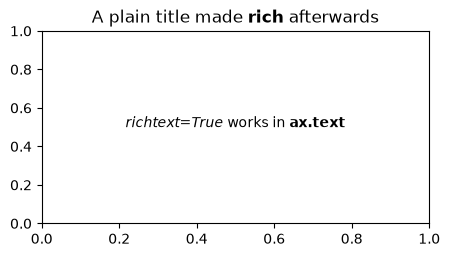

In [7]:
fig, ax = plt.subplots(figsize=(5, 2.5))
ax.set_title("A plain title made **rich** afterwards")
ggtext.richify(ax.title)
ax.text(0.5, 0.5, "*richtext=True* works in **ax.text**", ha="center", richtext=True)
plt.show()

## Where next?

- `docs/syntax.md`: everything you can write inside a label
- `docs/plotnine.md` and `docs/matplotlib.md`: every function and parameter
- `docs/design.md`: how this works, and the answer to plotnine issue #612